# Exploratory Data Analysis

## Introduction

This exploratory data analysis examines the structure, quality, distributions, and relationships within the 2026 EPA PM2.5 dataset in preparation for the project's predictive analysis. The EDA focuses specifically on variables relevant to identifying unusually elevated PM2.5 conditions and predicting next-day PM2.5 concentrations.

The analysis will explore geographic and temporal patterns, recent PM2.5 measurements, monitoring-station coverage, and relationships between current and future PM2.5 concentrations. These findings will also help assess the suitability of the proposed classification methods (Logistic Regression and Decision Tree) and regression methods (Multiple Linear Regression and Random Forest).

## Dataset Overview

The dataset was obtained from the **U.S. Environmental Protection Agency (EPA) Air Quality System (AQS)** and contains daily PM2.5 measurements for 2026. Before beginning the full EDA, the dataset structure, observation count, available variables, date range, geographic coverage, and monitoring-station coverage will be reviewed.

The primary variable of interest is **Arithmetic Mean**, which represents daily average PM2.5 concentration. Geographic, temporal, and monitoring-site variables will also be used to support the two research questions and the proposed predictive methods.

### Data Import

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("daily_88101_2026 - Copy.csv")

### Dataset Structure

In [2]:
print("Observations:", df.shape[0])
print("Variables:", df.shape[1])

Observations: 177365
Variables: 29


In [3]:
print("VARIABLE NAMES")
print("--------------")

for column in df.columns:
    print(column)

VARIABLE NAMES
--------------
State Code
County Code
Site Num
Parameter Code
POC
Latitude
Longitude
Datum
Parameter Name
Sample Duration
Pollutant Standard
Date Local
Units of Measure
Event Type
Observation Count
Observation Percent
Arithmetic Mean
1st Max Value
1st Max Hour
AQI
Method Code
Method Name
Local Site Name
Address
State Name
County Name
City Name
CBSA Name
Date of Last Change


### Data Coverage

In [4]:
df["Date Local"] = pd.to_datetime(df["Date Local"])

print("DATE COVERAGE")
print("-------------")
print("First Date:", df["Date Local"].min())
print("Last Date:", df["Date Local"].max())
print("Unique Dates:", df["Date Local"].nunique())

DATE COVERAGE
-------------
First Date: 2026-01-01 00:00:00
Last Date: 2026-05-31 00:00:00
Unique Dates: 151


### Geographic Coverage

In [5]:
us_states = df[
    ~df["State Name"].isin([
        "Country Of Mexico",
        "Puerto Rico",
        "District Of Columbia"
    ])
].copy()

print("Analysis Observations:", us_states.shape[0])
print("U.S. States Represented:", us_states["State Name"].nunique())

Analysis Observations: 175567
U.S. States Represented: 47


In [6]:
monitoring_locations = us_states[
    ["State Code", "County Code", "Site Num"]
].drop_duplicates().shape[0]

print("GEOGRAPHIC COVERAGE")
print("-------------------")
print("States:", us_states["State Name"].nunique())
print("Counties:", us_states["County Name"].nunique())
print("Cities:", us_states["City Name"].nunique())
print("Metropolitan Areas:", us_states["CBSA Name"].nunique())
print("Monitoring Locations:", monitoring_locations)

GEOGRAPHIC COVERAGE
-------------------
States: 47
Counties: 438
Cities: 585
Metropolitan Areas: 323
Monitoring Locations: 846


## Data Preparation

Before beginning the exploratory analysis, the dataset was evaluated for missing values, duplicate records, and multiple observations recorded for the same monitoring station and date. These checks are necessary to create consistent daily PM2.5 measurements for each monitoring location and prepare the data for the two research questions.

Additional preparation will include creating the geographic, temporal, recent PM2.5, elevated-pollution, and next-day PM2.5 variables needed for the proposed classification and regression analyses.

### Missing Values

In [7]:
missing_values = pd.DataFrame({
    "Missing Count": us_states.isnull().sum(),
    "Percent Missing": (us_states.isnull().mean() * 100).round(2)
})

missing_values

,Missing Count,Percent Missing
State Code,0,0.00
County Code,0,0.00
Site Num,0,0.00
Parameter Code,0,0.00
POC,0,0.00
Latitude,0,0.00
Longitude,0,0.00
Datum,0,0.00
Parameter Name,0,0.00
Sample Duration,0,0.00


### Duplicate Records

In [8]:
print("Exact duplicate rows:", us_states.duplicated().sum())

Exact duplicate rows: 0


### Repeated Station-Day Records

Although there are no exact duplicate rows, most station-days contain multiple records. The 175,567 observations represent **78,680 unique station-day combinations**, with an average of 2.23 records and as many as six records for the same station and date.

These records cannot be treated as separate daily observations when creating recent and next-day PM2.5 variables. The differences between repeated records will therefore be examined before creating a standardized station-day dataset.

In [9]:
station_day_counts = (
    us_states.groupby(
        ["State Code", "County Code", "Site Num", "Date Local"]
    )
    .size()
)

print("Unique station-days:", len(station_day_counts))
print("Average records per station-day:", round(station_day_counts.mean(), 2))
print("Maximum records per station-day:", station_day_counts.max())
print("Station-days with multiple records:", (station_day_counts > 1).sum())

Unique station-days: 78680
Average records per station-day: 2.23
Maximum records per station-day: 6
Station-days with multiple records: 75591


### Sampling Configurations

The repeated station-day records reflect differences in how PM2.5 measurements are collected and reported rather than duplicate observations. The dataset contains three sampling durations and multiple POC values, indicating that some monitoring locations report measurements from different instruments or sampling configurations.

Because the research questions focus on **daily PM2.5 conditions**, these differences need to be standardized before creating recent and next-day PM2.5 variables.

In [10]:
print("SAMPLE DURATION")
print(us_states["Sample Duration"].value_counts())

print("\nPOC")
print(us_states["POC"].value_counts().sort_index())

print("\nPOLLUTANT STANDARD")
print(us_states["Pollutant Standard"].value_counts(dropna=False))

SAMPLE DURATION
Sample Duration
1 HOUR           82068
24-HR BLK AVG    81151
24 HOUR          12348
Name: count, dtype: int64

POC
POC
1      33094
2      11138
3     103780
4      18804
5       5151
6       1990
7        416
8        304
9        538
23       352
Name: count, dtype: int64

POLLUTANT STANDARD
Pollutant Standard
PM25 24-hour 2012    93499
NaN                  82068
Name: count, dtype: int64


### Daily PM2.5 Records

In [11]:
daily_records = us_states[
    us_states["Sample Duration"].isin([
        "24-HR BLK AVG",
        "24 HOUR"
    ])
].copy()

daily_station_counts = (
    daily_records.groupby(
        ["State Code", "County Code", "Site Num", "Date Local"]
    )
    .size()
)

print("DAILY PM2.5 RECORDS")
print("-------------------")
print("Rows:", len(daily_records))
print("Unique station-days:", len(daily_station_counts))
print(
    "Station-days with multiple records:",
    (daily_station_counts > 1).sum()
)
print(
    "Maximum records per station-day:",
    daily_station_counts.max()
)

DAILY PM2.5 RECORDS
-------------------
Rows: 93499
Unique station-days: 77940
Station-days with multiple records: 13244
Maximum records per station-day: 4


### Repeated Daily Record Evaluation

In [12]:
duplicate_daily = daily_records[
    daily_records.duplicated(
        subset=[
            "State Code",
            "County Code",
            "Site Num",
            "Date Local"
        ],
        keep=False
    )
]

print("POC COUNTS AMONG REPEATED STATION-DAYS")
print("---------------------------------------")
print(duplicate_daily["POC"].value_counts().sort_index())

print("\nSAMPLE DURATION AMONG REPEATED STATION-DAYS")
print("--------------------------------------------")
print(duplicate_daily["Sample Duration"].value_counts())

POC COUNTS AMONG REPEATED STATION-DAYS
---------------------------------------
POC
1     8596
2     3032
3     9673
4     5199
5     1092
6      701
7       37
9      298
23     175
Name: count, dtype: int64

SAMPLE DURATION AMONG REPEATED STATION-DAYS
--------------------------------------------
Sample Duration
24-HR BLK AVG    18887
24 HOUR           9916
Name: count, dtype: int64


In [13]:
pm25_variation = (
    duplicate_daily.groupby(
        ["State Code", "County Code", "Site Num", "Date Local"]
    )["Arithmetic Mean"]
    .agg(["count", "nunique", "min", "max"])
)

print("Repeated station-days:", len(pm25_variation))

print(
    "Same PM2.5 value across records:",
    (pm25_variation["nunique"] == 1).sum()
)

print(
    "Different PM2.5 values across records:",
    (pm25_variation["nunique"] > 1).sum()
)

print("\nDifference between highest and lowest PM2.5:")
print(
    (pm25_variation["max"] - pm25_variation["min"]).describe()
)

Repeated station-days: 13244
Same PM2.5 value across records: 607
Different PM2.5 values across records: 12637

Difference between highest and lowest PM2.5:
count    13244.000000
mean         1.215109
std          1.457725
min          0.000000
25%          0.300000
50%          0.800000
75%          1.600000
max         37.400000
dtype: float64


### Standardized Station-Day Dataset

The daily records were aggregated to create one PM2.5 observation for each monitoring station and date. When multiple valid daily measurements were available, their `Arithmetic Mean` values were averaged so that stations with multiple instruments or reporting configurations would not be represented more than once per day.

The resulting dataset contains **77,940 observations and 77,940 unique station-day combinations**. This standardized dataset will be used for the remaining EDA and for creating the recent and next-day PM2.5 variables required by the research questions.

In [14]:
station_daily = (
    daily_records.groupby(
        [
            "State Code",
            "County Code",
            "Site Num",
            "Date Local"
        ],
        as_index=False
    )
    .agg({
        "Arithmetic Mean": "mean",
        "Latitude": "first",
        "Longitude": "first",
        "State Name": "first",
        "County Name": "first",
        "City Name": "first",
        "CBSA Name": "first",
        "Observation Percent": "mean"
    })
)

print("STANDARDIZED STATION-DAY DATASET")
print("--------------------------------")
print("Observations:", len(station_daily))
print(
    "Unique station-days:",
    station_daily[
        ["State Code", "County Code", "Site Num", "Date Local"]
    ].drop_duplicates().shape[0]
)

STANDARDIZED STATION-DAY DATASET
--------------------------------
Observations: 77940
Unique station-days: 77940


In [15]:
print("STANDARDIZED DATA CHECK")
print("-----------------------")

print("Missing PM2.5 values:", station_daily["Arithmetic Mean"].isna().sum())
print("Exact duplicate rows:", station_daily.duplicated().sum())

print(
    "Duplicate station-days:",
    station_daily.duplicated(
        subset=["State Code", "County Code", "Site Num", "Date Local"]
    ).sum()
)

print(
    "Monitoring stations:",
    station_daily[
        ["State Code", "County Code", "Site Num"]
    ].drop_duplicates().shape[0]
)

print(
    "Date range:",
    station_daily["Date Local"].min(),
    "to",
    station_daily["Date Local"].max()
)

STANDARDIZED DATA CHECK
-----------------------
Missing PM2.5 values: 0
Exact duplicate rows: 0
Duplicate station-days: 0
Monitoring stations: 846
Date range: 2026-01-01 00:00:00 to 2026-05-31 00:00:00


### Temporal and Geographic Features

Additional temporal variables were created from `Date Local`, including month, day of week, and day of year. These variables will allow the EDA to examine whether PM2.5 conditions vary over time and may later serve as predictors in the proposed models.

A broader `Region` variable was also created from state information to support geographic comparisons. All observations were successfully classified into the **Northeast, Midwest, South, or West**, although the number of observations differs across regions.

In [16]:
station_daily["Month"] = station_daily["Date Local"].dt.month
station_daily["Month Name"] = station_daily["Date Local"].dt.month_name()
station_daily["Day of Week"] = station_daily["Date Local"].dt.day_name()
station_daily["Day of Year"] = station_daily["Date Local"].dt.dayofyear

station_daily[
    ["Date Local", "Month", "Month Name", "Day of Week", "Day of Year"]
].head()

,Date Local,Month,Month Name,Day of Week,Day of Year
0,2026-01-01,1,January,Thursday,1
1,2026-01-02,1,January,Friday,2
2,2026-01-03,1,January,Saturday,3
3,2026-01-04,1,January,Sunday,4
4,2026-01-05,1,January,Monday,5


In [17]:
northeast = [
    "Connecticut", "Maine", "Massachusetts", "New Hampshire",
    "Rhode Island", "Vermont", "New Jersey", "New York",
    "Pennsylvania"
]

midwest = [
    "Indiana", "Illinois", "Michigan", "Ohio", "Wisconsin",
    "Iowa", "Kansas", "Minnesota", "Missouri", "Nebraska",
    "North Dakota", "South Dakota"
]

south = [
    "Delaware", "Florida", "Georgia", "Maryland",
    "North Carolina", "South Carolina", "Virginia",
    "West Virginia", "Alabama", "Kentucky", "Mississippi",
    "Tennessee", "Arkansas", "Louisiana", "Oklahoma", "Texas"
]

west = [
    "Arizona", "Colorado", "Idaho", "Montana", "Nevada",
    "New Mexico", "Utah", "Wyoming", "Alaska", "California",
    "Hawaii", "Oregon", "Washington"
]

def assign_region(state):
    if state in northeast:
        return "Northeast"
    elif state in midwest:
        return "Midwest"
    elif state in south:
        return "South"
    elif state in west:
        return "West"
    else:
        return "Unassigned"

station_daily["Region"] = station_daily["State Name"].apply(assign_region)

print(station_daily["Region"].value_counts())

Region
South        24337
West         22799
Midwest      21246
Northeast     9558
Name: count, dtype: int64


### Recent and Next-Day PM2.5 Variables

In [18]:
station_daily = station_daily.sort_values(
    ["State Code", "County Code", "Site Num", "Date Local"]
).reset_index(drop=True)

In [19]:
station_daily["Previous Day PM2.5"] = (
    station_daily.groupby(
        ["State Code", "County Code", "Site Num"]
    )["Arithmetic Mean"]
    .shift(1)
)

station_daily["Next Day PM2.5"] = (
    station_daily.groupby(
        ["State Code", "County Code", "Site Num"]
    )["Arithmetic Mean"]
    .shift(-1)
)

In [20]:
station_daily["Previous Date"] = (
    station_daily.groupby(
        ["State Code", "County Code", "Site Num"]
    )["Date Local"]
    .shift(1)
)

station_daily["Next Date"] = (
    station_daily.groupby(
        ["State Code", "County Code", "Site Num"]
    )["Date Local"]
    .shift(-1)
)

station_daily["Days Since Previous"] = (
    station_daily["Date Local"] - station_daily["Previous Date"]
).dt.days

station_daily["Days Until Next"] = (
    station_daily["Next Date"] - station_daily["Date Local"]
).dt.days

In [21]:
print(
    "Valid previous-day observations:",
    (station_daily["Days Since Previous"] == 1).sum()
)

print(
    "Valid next-day observations:",
    (station_daily["Days Until Next"] == 1).sum()
)

print("\nGaps between consecutive station observations:")
print(
    station_daily["Days Until Next"]
    .value_counts()
    .sort_index()
    .head(10)
)

Valid previous-day observations: 74649
Valid next-day observations: 74649

Gaps between consecutive station observations:
Days Until Next
1.0     74649
2.0       217
3.0      1789
4.0        49
5.0        63
6.0       202
7.0        14
8.0         8
9.0        20
10.0        4
Name: count, dtype: int64


In [22]:
station_daily.loc[
    station_daily["Days Since Previous"] != 1,
    "Previous Day PM2.5"
] = pd.NA

station_daily.loc[
    station_daily["Days Until Next"] != 1,
    "Next Day PM2.5"
] = pd.NA

In [23]:
print(
    "Usable previous-day PM2.5 values:",
    station_daily["Previous Day PM2.5"].notna().sum()
)

print(
    "Usable next-day PM2.5 values:",
    station_daily["Next Day PM2.5"].notna().sum()
)

Usable previous-day PM2.5 values: 74649
Usable next-day PM2.5 values: 74649


### Elevated PM2.5 Threshold Exploration

In [24]:
print("PM2.5 THRESHOLD EXPLORATION")
print("---------------------------")

thresholds = [12, 15, 20, 25]

for threshold in thresholds:
    count = (station_daily["Arithmetic Mean"] >= threshold).sum()
    percent = (
        (station_daily["Arithmetic Mean"] >= threshold).mean() * 100
    )

    print(
        f">= {threshold} µg/m³: "
        f"{count} observations ({percent:.2f}%)"
    )

PM2.5 THRESHOLD EXPLORATION
---------------------------
>= 12 µg/m³: 11076 observations (14.21%)
>= 15 µg/m³: 6135 observations (7.87%)
>= 20 µg/m³: 2163 observations (2.78%)
>= 25 µg/m³: 778 observations (1.00%)


### Data Preparation Summary

The preparation process produced a standardized dataset containing **77,940 unique station-day observations across 846 monitoring stations**. The dataset contains no missing values for the primary PM2.5 measurement and no duplicate station-days. Geographic regions and temporal characteristics were created, and **74,649 valid consecutive-day observations** are available for analyses involving recent and next-day PM2.5.

The prepared data therefore provide the variables and temporal structure needed to begin exploratory analysis for both the elevated-pollution classification question and the next-day PM2.5 prediction question.

## Descriptive Statistics

Descriptive statistics were used to summarize PM2.5 concentrations and the geographic and temporal composition of the standardized station-day dataset. These summaries provide an initial understanding of typical pollution levels, variability, extreme observations, and differences in data availability across regions and time periods before examining relationships among variables.

In [25]:
print("DAILY PM2.5 DESCRIPTIVE STATISTICS")
print("----------------------------------")

print(
    station_daily["Arithmetic Mean"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

DAILY PM2.5 DESCRIPTIVE STATISTICS
----------------------------------
count    77940.000000
mean         7.237170
std          5.244352
min         -3.400000
25%          3.900000
50%          6.000000
75%          9.200000
90%         13.700000
95%         17.100000
99%         24.930500
max        183.800000
Name: Arithmetic Mean, dtype: float64


In [26]:
print("RECENT AND NEXT-DAY PM2.5")
print("-------------------------")

station_daily[
    [
        "Arithmetic Mean",
        "Previous Day PM2.5",
        "Next Day PM2.5"
    ]
].describe()

RECENT AND NEXT-DAY PM2.5
-------------------------


,Arithmetic Mean,Previous Day PM2.5,Next Day PM2.5
count,77940.000000,74649.000000,74649.000000
mean,7.237170,7.232451,7.214104
std,5.244352,5.254174,5.192075
min,-3.400000,-3.400000,-3.400000
25%,3.900000,3.800000,3.900000
50%,6.000000,5.900000,5.950000
75%,9.200000,9.200000,9.200000
max,183.800000,183.800000,183.800000


### Regional Summary

In [27]:
region_summary = (
    station_daily.groupby("Region")
    .agg(
        Observations=("Arithmetic Mean", "count"),
        Mean_PM25=("Arithmetic Mean", "mean"),
        Median_PM25=("Arithmetic Mean", "median"),
        Std_PM25=("Arithmetic Mean", "std")
    )
    .round(2)
)

region_summary

,Observations,Mean_PM25,Median_PM25,Std_PM25
Region,,,,
Midwest,21246,7.73,6.3,5.11
Northeast,9558,7.07,5.8,4.65
South,24337,8.12,7.0,5.23
West,22799,5.90,4.5,5.35


### Monthly Summary

In [28]:
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May"
]

monthly_summary = (
    station_daily.groupby("Month Name")
    .agg(
        Observations=("Arithmetic Mean", "count"),
        Mean_PM25=("Arithmetic Mean", "mean"),
        Median_PM25=("Arithmetic Mean", "median")
    )
    .reindex(month_order)
    .round(2)
)

monthly_summary

,Observations,Mean_PM25,Median_PM25
Month Name,,,
January,23766,7.31,5.9
February,20949,8.03,6.7
March,21331,7.14,5.9
April,8254,6.00,5.3
May,3640,5.61,5.1


### Descriptive Statistics Summary

Daily PM2.5 concentrations have a mean of **7.29** and a median of **6.00**, with most observations concentrated at relatively low levels and a smaller number of substantially elevated measurements. The 95th percentile is **17.10** and the 99th percentile is **25.00**, indicating a right-skewed distribution that will be examined further during the univariate analysis.

Initial summaries also show geographic and temporal differences. The **South has the highest average PM2.5 concentration (8.13)**, while the **West has the lowest (6.04)**. February has the highest monthly average (**8.09**), while May has the lowest (**5.61**). These preliminary differences suggest that geographic and temporal characteristics may be relevant to the proposed predictive analyses.

A small number of negative PM2.5 measurements were also identified and examined as a potential data-quality issue before continuing the analysis.

### Negative PM2.5 Measurements

In [29]:
negative_pm25 = station_daily[
    station_daily["Arithmetic Mean"] < 0
]

print("NEGATIVE PM2.5 VALUES")
print("--------------------")
print("Count:", len(negative_pm25))
print(
    "Percent:",
    round(len(negative_pm25) / len(station_daily) * 100, 3)
)

print("\nSummary:")
print(negative_pm25["Arithmetic Mean"].describe())

NEGATIVE PM2.5 VALUES
--------------------
Count: 508
Percent: 0.652

Summary:
count    508.000000
mean      -0.699311
std        0.567213
min       -3.400000
25%       -0.925000
50%       -0.600000
75%       -0.300000
max       -0.100000
Name: Arithmetic Mean, dtype: float64


In [30]:
station_daily.loc[
    station_daily["Arithmetic Mean"] < 0,
    "Arithmetic Mean"
] = pd.NA

print(
    "Negative PM2.5 values remaining:",
    (station_daily["Arithmetic Mean"] < 0).sum()
)

print(
    "Missing PM2.5 values after cleaning:",
    station_daily["Arithmetic Mean"].isna().sum()
)

Negative PM2.5 values remaining: 0
Missing PM2.5 values after cleaning: 508


### Recalculation After Data Cleaning

In [31]:
station_daily["Previous Day PM2.5"] = (
    station_daily.groupby(
        ["State Code", "County Code", "Site Num"]
    )["Arithmetic Mean"]
    .shift(1)
)

station_daily["Next Day PM2.5"] = (
    station_daily.groupby(
        ["State Code", "County Code", "Site Num"]
    )["Arithmetic Mean"]
    .shift(-1)
)

# Keep only true consecutive-day measurements
station_daily.loc[
    station_daily["Days Since Previous"] != 1,
    "Previous Day PM2.5"
] = pd.NA

station_daily.loc[
    station_daily["Days Until Next"] != 1,
    "Next Day PM2.5"
] = pd.NA

In [32]:
print(
    "Usable previous-day PM2.5 values:",
    station_daily["Previous Day PM2.5"].notna().sum()
)

print(
    "Usable next-day PM2.5 values:",
    station_daily["Next Day PM2.5"].notna().sum()
)

print(
    "Negative previous-day values:",
    (station_daily["Previous Day PM2.5"] < 0).sum()
)

print(
    "Negative next-day values:",
    (station_daily["Next Day PM2.5"] < 0).sum()
)

Usable previous-day PM2.5 values: 74149
Usable next-day PM2.5 values: 74162
Negative previous-day values: 0
Negative next-day values: 0


### PM2.5 Distribution

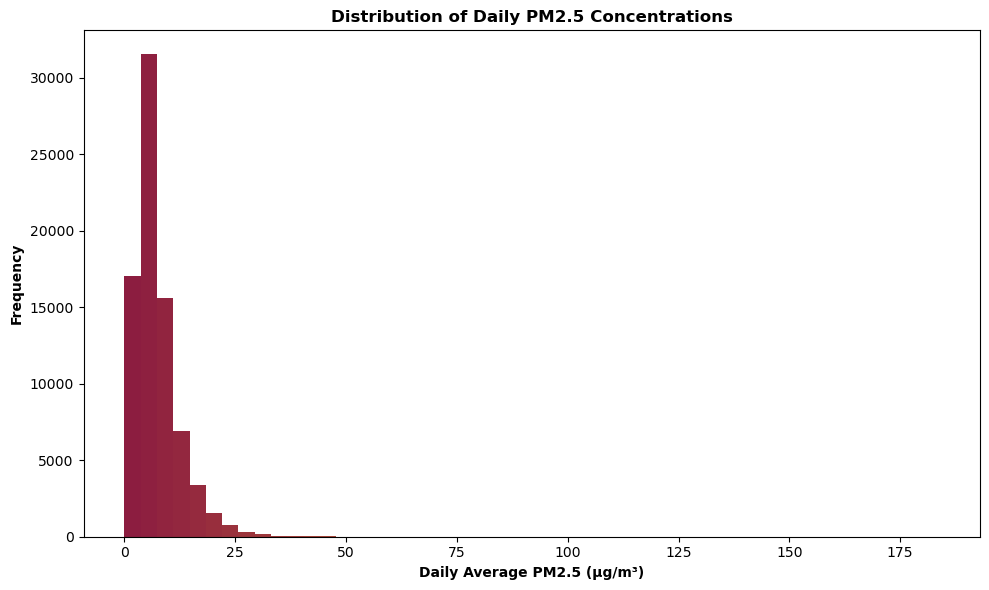

In [33]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

plt.figure(figsize=(10, 6))

# Create histogram and save the bars
counts, bins, patches = plt.hist(
    station_daily["Arithmetic Mean"].dropna(),
    bins=50
)

# Maroon → Gold gradient
maroon_gold = mcolors.LinearSegmentedColormap.from_list(
    "maroon_gold",
    ["#8C1D40", "#FFC627"]
)

# Apply gradient across histogram bars
colors = maroon_gold(np.linspace(0, 1, len(patches)))

for patch, color in zip(patches, colors):
    patch.set_facecolor(color)

plt.title(
    "Distribution of Daily PM2.5 Concentrations",
    fontweight="bold"
)

plt.xlabel(
    "Daily Average PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.ylabel(
    "Frequency",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

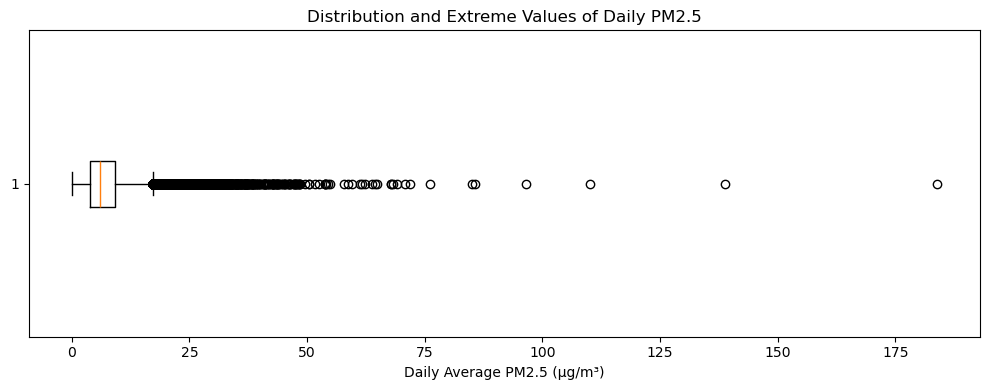

In [34]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    station_daily["Arithmetic Mean"].dropna(),
    vert=False
)

plt.title("Distribution and Extreme Values of Daily PM2.5")
plt.xlabel("Daily Average PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

### Geographic Observation Distribution

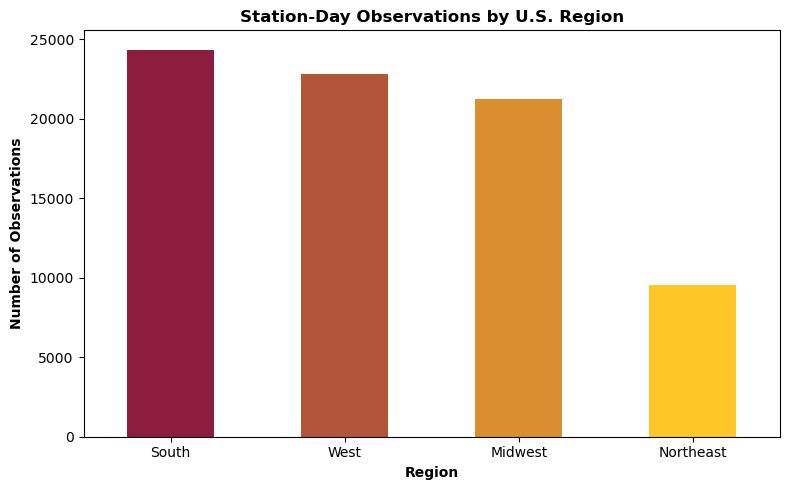

In [35]:
region_counts = station_daily["Region"].value_counts()

# Maroon → Gold gradient
colors = maroon_gold(
    np.linspace(0, 1, len(region_counts))
)

plt.figure(figsize=(8, 5))

region_counts.plot(
    kind="bar",
    color=colors
)

plt.title(
    "Station-Day Observations by U.S. Region",
    fontweight="bold"
)

plt.xlabel(
    "Region",
    fontweight="bold"
)

plt.ylabel(
    "Number of Observations",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Monthly Observation Distribution

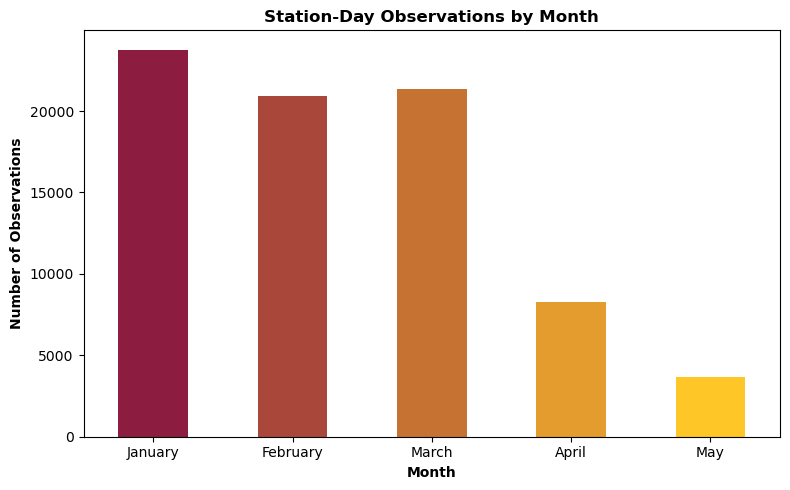

In [36]:
month_counts = (
    station_daily["Month Name"]
    .value_counts()
    .reindex(["January", "February", "March", "April", "May"])
)

# Maroon → Gold gradient
colors = maroon_gold(
    np.linspace(0, 1, len(month_counts))
)

plt.figure(figsize=(8, 5))

month_counts.plot(
    kind="bar",
    color=colors
)

plt.title(
    "Station-Day Observations by Month",
    fontweight="bold"
)

plt.xlabel(
    "Month",
    fontweight="bold"
)

plt.ylabel(
    "Number of Observations",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## Current and Next-Day PM2.5 Relationship

In [37]:
next_day_data = station_daily[
    ["Arithmetic Mean", "Next Day PM2.5"]
].dropna()

correlation = next_day_data[
    "Arithmetic Mean"
].corr(
    next_day_data["Next Day PM2.5"]
)

print(
    "Correlation between current and next-day PM2.5:",
    round(correlation, 3)
)

Correlation between current and next-day PM2.5: 0.628


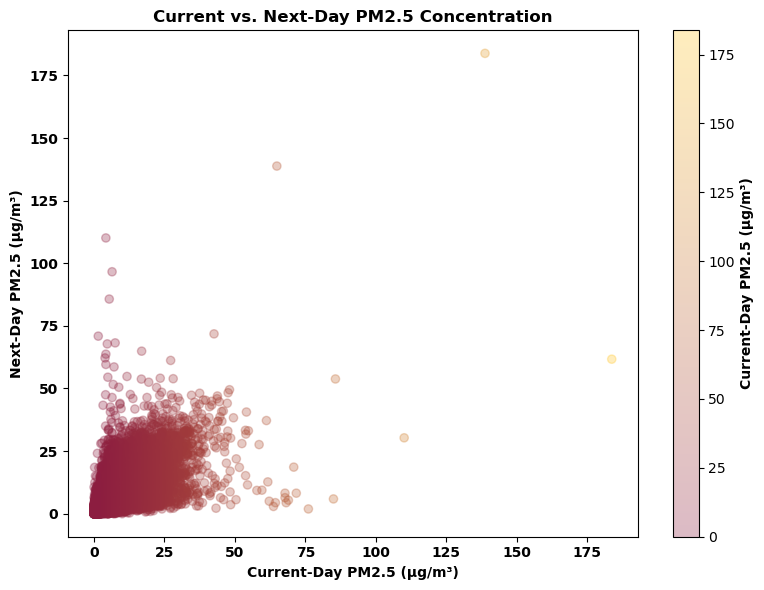

In [38]:
plt.figure(figsize=(8, 6))

plt.scatter(
    next_day_data["Arithmetic Mean"],
    next_day_data["Next Day PM2.5"],
    c=next_day_data["Arithmetic Mean"],
    cmap=maroon_gold,
    alpha=0.3
)

cbar = plt.colorbar()
cbar.set_label(
    "Current-Day PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.title(
    "Current vs. Next-Day PM2.5 Concentration",
    fontweight="bold"
)

plt.xlabel(
    "Current-Day PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.ylabel(
    "Next-Day PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.xticks(fontweight="bold")
plt.yticks(fontweight="bold")

plt.tight_layout()
plt.show()

### Current and Next-Day PM2.5

Current-day and next-day PM2.5 concentrations have a **positive correlation of 0.628**, indicating that higher PM2.5 concentrations on one day tend to be associated with higher concentrations the following day. The scatterplot shows this positive relationship while also revealing greater variability and several extreme observations at higher concentrations.

This relationship supports the use of recent PM2.5 measurements as predictors of next-day concentration and provides a basis for comparing **Multiple Linear Regression and Random Forest** in the predictive analysis.

### PM2.5 Concentrations by Region

<Figure size 900x600 with 0 Axes>

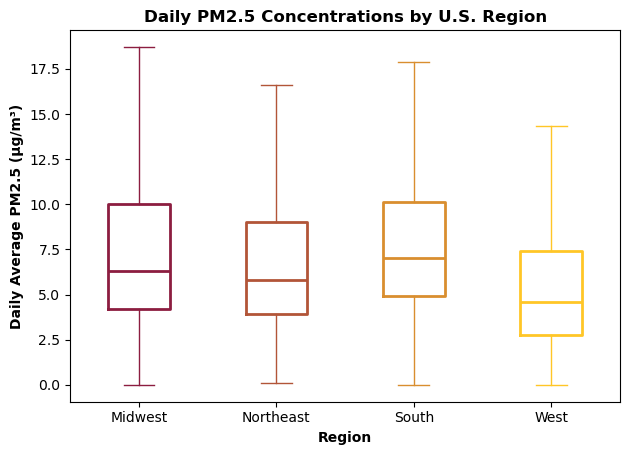

In [39]:
plt.figure(figsize=(9, 6))

ax = station_daily.boxplot(
    column="Arithmetic Mean",
    by="Region",
    grid=False,
    showfliers=False,
    patch_artist=False,
    return_type="axes"
)

ax = plt.gca()

# Maroon → Gold gradient
colors = maroon_gold(
    np.linspace(0, 1, 4)
)

# Each region has:
# 1 box, 2 whiskers, 2 caps, 1 median
for i, color in enumerate(colors):
    
    # Box outline
    ax.lines[i * 6].set_color(color)
    ax.lines[i * 6].set_linewidth(2)

    # Whiskers
    ax.lines[i * 6 + 1].set_color(color)
    ax.lines[i * 6 + 2].set_color(color)

    # Caps
    ax.lines[i * 6 + 3].set_color(color)
    ax.lines[i * 6 + 4].set_color(color)

    # Median
    ax.lines[i * 6 + 5].set_color(color)
    ax.lines[i * 6 + 5].set_linewidth(2)

plt.title(
    "Daily PM2.5 Concentrations by U.S. Region",
    fontweight="bold"
)

plt.suptitle("")

plt.xlabel(
    "Region",
    fontweight="bold"
)

plt.ylabel(
    "Daily Average PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

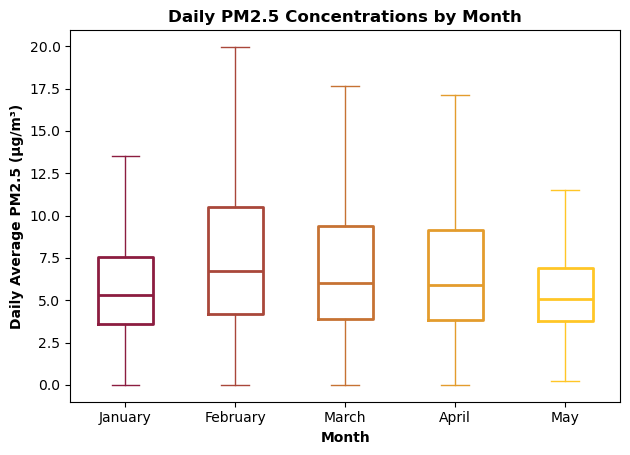

In [40]:
month_order = ["January", "February", "March", "April", "May"]

plt.figure(figsize=(10, 6))

ax = station_daily.boxplot(
    column="Arithmetic Mean",
    by="Month Name",
    grid=False,
    showfliers=False,
    positions=range(1, 6),
    patch_artist=False,
    return_type="axes"
)

ax = plt.gca()

# Maroon → Gold gradient
colors = maroon_gold(
    np.linspace(0, 1, 5)
)

# Apply gradient to boxplot lines
for i, color in enumerate(colors):

    # Box outline
    ax.lines[i * 6].set_color(color)
    ax.lines[i * 6].set_linewidth(2)

    # Whiskers
    ax.lines[i * 6 + 1].set_color(color)
    ax.lines[i * 6 + 2].set_color(color)

    # Caps
    ax.lines[i * 6 + 3].set_color(color)
    ax.lines[i * 6 + 4].set_color(color)

    # Median
    ax.lines[i * 6 + 5].set_color(color)
    ax.lines[i * 6 + 5].set_linewidth(2)

plt.title(
    "Daily PM2.5 Concentrations by Month",
    fontweight="bold"
)

plt.suptitle("")

plt.xlabel(
    "Month",
    fontweight="bold"
)

plt.ylabel(
    "Daily Average PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.xticks(
    range(1, 6),
    month_order
)

plt.tight_layout()
plt.show()

### Elevated PM2.5 Classification

In [41]:
station_daily["Elevated PM2.5 (15)"] = (
    station_daily["Arithmetic Mean"] >= 15
).astype("Int64")

elevated_counts = station_daily[
    "Elevated PM2.5 (15)"
].value_counts().sort_index()

elevated_percent = station_daily[
    "Elevated PM2.5 (15)"
].value_counts(normalize=True).sort_index() * 100

print("CANDIDATE ELEVATED PM2.5 CLASSIFICATION")
print("---------------------------------------")
print("Not Elevated:", elevated_counts.get(0, 0))
print("Elevated:", elevated_counts.get(1, 0))

print("\nPercent:")
print("Not Elevated:", round(elevated_percent.get(0, 0), 2), "%")
print("Elevated:", round(elevated_percent.get(1, 0), 2), "%")

CANDIDATE ELEVATED PM2.5 CLASSIFICATION
---------------------------------------
Not Elevated: 71805
Elevated: 6135

Percent:
Not Elevated: 92.13 %
Elevated: 7.87 %


### Elevated PM2.5 by Region

Region
Midwest      9.65
South        8.21
Northeast    6.71
West         6.34
Name: Elevated PM2.5 (15), dtype: Float64


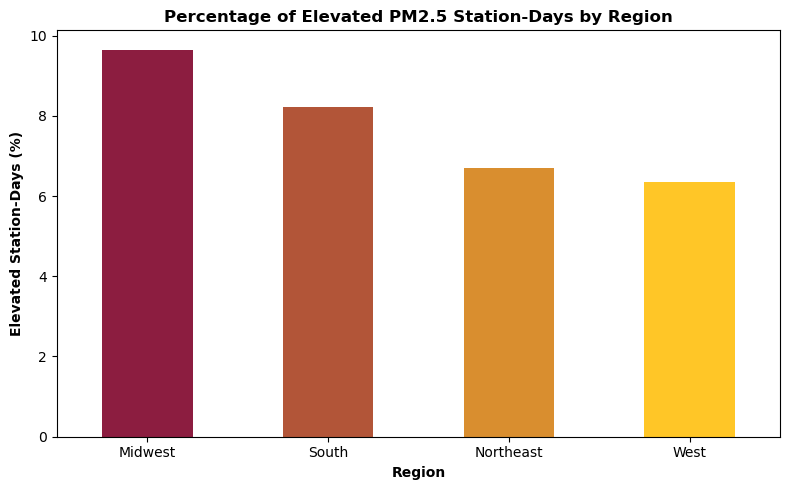

In [42]:
elevated_by_region = (
    station_daily.groupby("Region")["Elevated PM2.5 (15)"]
    .mean() * 100
).sort_values(ascending=False)

print(elevated_by_region.round(2))

# Maroon → Gold gradient
colors = maroon_gold(
    np.linspace(0, 1, len(elevated_by_region))
)

plt.figure(figsize=(8, 5))

elevated_by_region.plot(
    kind="bar",
    color=colors
)

plt.title(
    "Percentage of Elevated PM2.5 Station-Days by Region",
    fontweight="bold"
)

plt.xlabel(
    "Region",
    fontweight="bold"
)

plt.ylabel(
    "Elevated Station-Days (%)",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Elevated PM2.5 by Month

Month Name
January      8.78
February    10.61
March        7.49
April        2.33
May          1.02
Name: Elevated PM2.5 (15), dtype: Float64


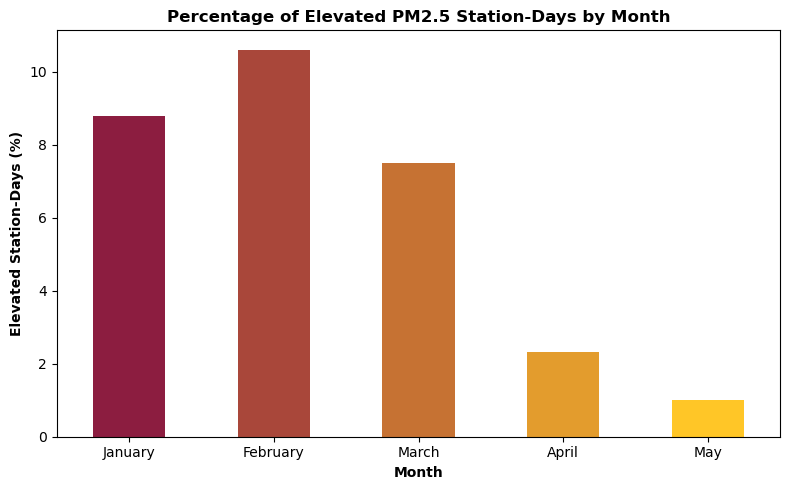

In [43]:
elevated_by_month = (
    station_daily.groupby("Month Name")["Elevated PM2.5 (15)"]
    .mean() * 100
).reindex(["January", "February", "March", "April", "May"])

print(elevated_by_month.round(2))

# Maroon → Gold gradient
colors = maroon_gold(
    np.linspace(0, 1, len(elevated_by_month))
)

plt.figure(figsize=(8, 5))

elevated_by_month.plot(
    kind="bar",
    color=colors
)

plt.title(
    "Percentage of Elevated PM2.5 Station-Days by Month",
    fontweight="bold"
)

plt.xlabel(
    "Month",
    fontweight="bold"
)

plt.ylabel(
    "Elevated Station-Days (%)",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Previous-Day PM2.5 and Elevated Pollution

In [44]:
elevated_recent = station_daily[
    ["Previous Day PM2.5", "Elevated PM2.5 (15)"]
].dropna()

recent_by_class = (
    elevated_recent.groupby("Elevated PM2.5 (15)")["Previous Day PM2.5"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

recent_by_class

,count,mean,median,std
Elevated PM2.5 (15),,,,
0,68314,6.62,5.60,4.32
1,5835,15.09,14.05,7.95


<Figure size 800x500 with 0 Axes>

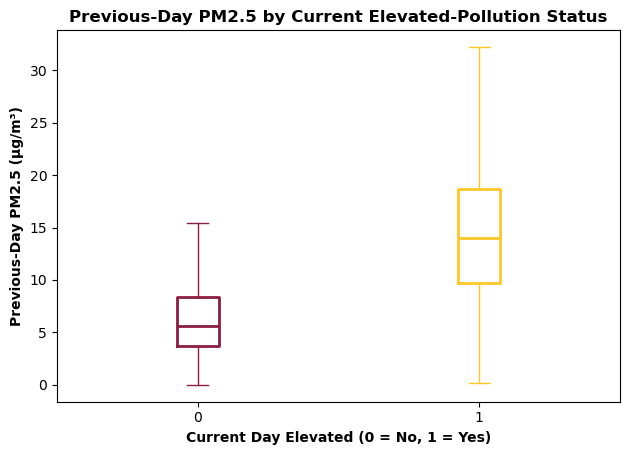

In [45]:
plt.figure(figsize=(8, 5))

ax = elevated_recent.boxplot(
    column="Previous Day PM2.5",
    by="Elevated PM2.5 (15)",
    grid=False,
    showfliers=False,
    patch_artist=False,
    return_type="axes"
)

ax = plt.gca()

# Maroon and Gold
colors = ["#8C1D40", "#FFC627"]

# Apply colors to boxplot lines
for i, color in enumerate(colors):

    # Box outline
    ax.lines[i * 6].set_color(color)
    ax.lines[i * 6].set_linewidth(2)

    # Whiskers
    ax.lines[i * 6 + 1].set_color(color)
    ax.lines[i * 6 + 2].set_color(color)

    # Caps
    ax.lines[i * 6 + 3].set_color(color)
    ax.lines[i * 6 + 4].set_color(color)

    # Median
    ax.lines[i * 6 + 5].set_color(color)
    ax.lines[i * 6 + 5].set_linewidth(2)

plt.title(
    "Previous-Day PM2.5 by Current Elevated-Pollution Status",
    fontweight="bold"
)

plt.suptitle("")

plt.xlabel(
    "Current Day Elevated (0 = No, 1 = Yes)",
    fontweight="bold"
)

plt.ylabel(
    "Previous-Day PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Current and Next-Day PM2.5 Correlation by Region

In [46]:
regional_correlations = (
    next_day_data
    .join(station_daily["Region"])
    .groupby("Region")
    .apply(
        lambda x: x["Arithmetic Mean"].corr(x["Next Day PM2.5"]),
        include_groups=False
    )
    .sort_values(ascending=False)
)

print("CURRENT VS. NEXT-DAY PM2.5 CORRELATION BY REGION")
print("------------------------------------------------")
print(regional_correlations.round(3))

CURRENT VS. NEXT-DAY PM2.5 CORRELATION BY REGION
------------------------------------------------
Region
West         0.791
Midwest      0.591
South        0.519
Northeast    0.486
dtype: float64


#### Observation Completeness Check

In [47]:
print("Unique Observation Percent values:")
print(station_daily["Observation Percent"].value_counts().sort_index())

Unique Observation Percent values:
Observation Percent
100.0    77940
Name: count, dtype: int64


### Correlation Among Numerical Variables

In [48]:
correlation_variables = station_daily[
    [
        "Arithmetic Mean",
        "Previous Day PM2.5",
        "Next Day PM2.5",
        "Latitude",
        "Longitude",
        "Day of Year"
    ]
]

correlation_matrix = correlation_variables.corr()

correlation_matrix.round(3)

,Arithmetic Mean,Previous Day PM2.5,Next Day PM2.5,Latitude,Longitude,Day of Year
Arithmetic Mean,1.000,0.628,0.628,-0.047,0.107,-0.095
Previous Day PM2.5,0.628,1.000,0.373,-0.044,0.111,-0.093
Next Day PM2.5,0.628,0.373,1.000,-0.042,0.116,-0.091
Latitude,-0.047,-0.044,-0.042,1.000,0.209,0.037
Longitude,0.107,0.111,0.116,0.209,1.000,0.065
Day of Year,-0.095,-0.093,-0.091,0.037,0.065,1.000


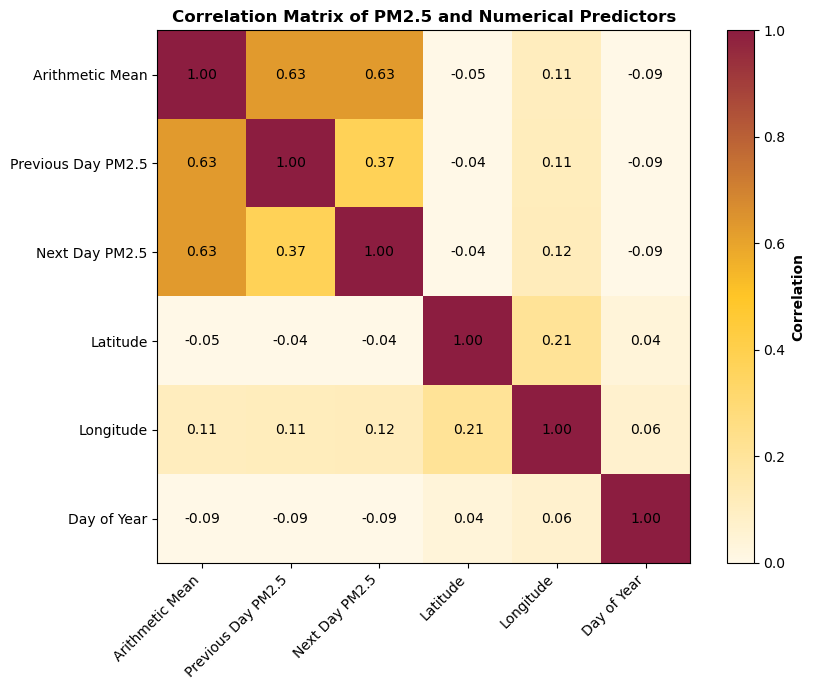

In [49]:
# Cream/Gold → Maroon gradient
correlation_colors = mcolors.LinearSegmentedColormap.from_list(
    "correlation_colors",
    ["#FFF8E7", "#FFC627", "#8C1D40"]
)

plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    cmap=correlation_colors,
    vmin=0,
    vmax=1
)

cbar = plt.colorbar()
cbar.set_label(
    "Correlation",
    fontweight="bold"
)

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title(
    "Correlation Matrix of PM2.5 and Numerical Predictors",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## Exploratory Visualizations

The following visualizations were selected to connect the patterns identified during the EDA to the proposed analytical methods. For Q1, the visuals focus on how recent PM2.5 and geographic characteristics relate to elevated-pollution conditions. For Q2, the visuals focus on the relationship between recent and next-day PM2.5 and whether that relationship varies geographically.

### Visual Support for RQ1: Elevated PM2.5 Classifications.

In [50]:
logistic_visual = station_daily[
    ["Previous Day PM2.5", "Elevated PM2.5 (15)"]
].dropna().copy()

logistic_visual["Previous PM2.5 Level"] = pd.cut(
    logistic_visual["Previous Day PM2.5"],
    bins=[0, 5, 10, 15, 20, 25, float("inf")],
    labels=["0–5", "5–10", "10–15", "15–20", "20–25", "25+"],
    include_lowest=True
)

elevated_rate = (
    logistic_visual.groupby(
        "Previous PM2.5 Level",
        observed=True
    )["Elevated PM2.5 (15)"]
    .mean() * 100
)

elevated_rate.round(2)

Previous PM2.5 Level
0–5       0.59
5–10      4.81
10–15    16.97
15–20    37.22
20–25    51.67
25+      66.67
Name: Elevated PM2.5 (15), dtype: Float64

### RQ1: Elevated PM2.5 by Previous-Day Level and Region

In [51]:
tree_visual = station_daily[
    ["Previous Day PM2.5", "Region", "Elevated PM2.5 (15)"]
].dropna().copy()

tree_visual["Previous PM2.5 Level"] = pd.cut(
    tree_visual["Previous Day PM2.5"],
    bins=[0, 5, 10, 15, 25, float("inf")],
    labels=["0–5", "5–10", "10–15", "15–25", "25+"],
    include_lowest=True
)

tree_pattern = (
    tree_visual.groupby(
        ["Previous PM2.5 Level", "Region"],
        observed=True
    )["Elevated PM2.5 (15)"]
    .mean()
    .mul(100)
    .unstack()
)

tree_pattern.round(2)

Region,Midwest,Northeast,South,West
Previous PM2.5 Level,,,,
0–5,0.48,0.82,1.27,0.24
5–10,6.72,5.93,4.71,2.06
10–15,19.25,16.4,14.6,18.62
15–25,39.67,30.56,34.36,57.89
25+,67.78,33.82,56.31,83.02


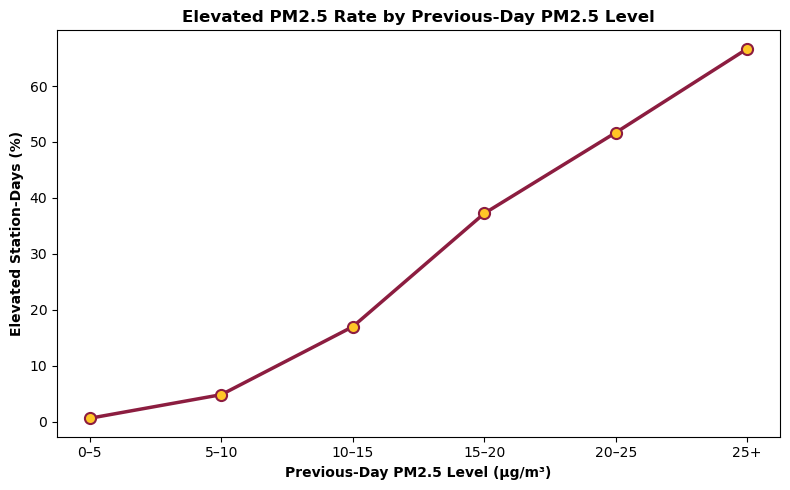

In [52]:
plt.figure(figsize=(8, 5))

plt.plot(
    elevated_rate.index.astype(str),
    elevated_rate.values,
    color="#8C1D40",        # Maroon line
    marker="o",
    markerfacecolor="#FFC627",  # Gold markers
    markeredgecolor="#8C1D40",
    markeredgewidth=1.5,
    linewidth=2.5,
    markersize=8
)

plt.title(
    "Elevated PM2.5 Rate by Previous-Day PM2.5 Level",
    fontweight="bold"
)

plt.xlabel(
    "Previous-Day PM2.5 Level (µg/m³)",
    fontweight="bold"
)

plt.ylabel(
    "Elevated Station-Days (%)",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

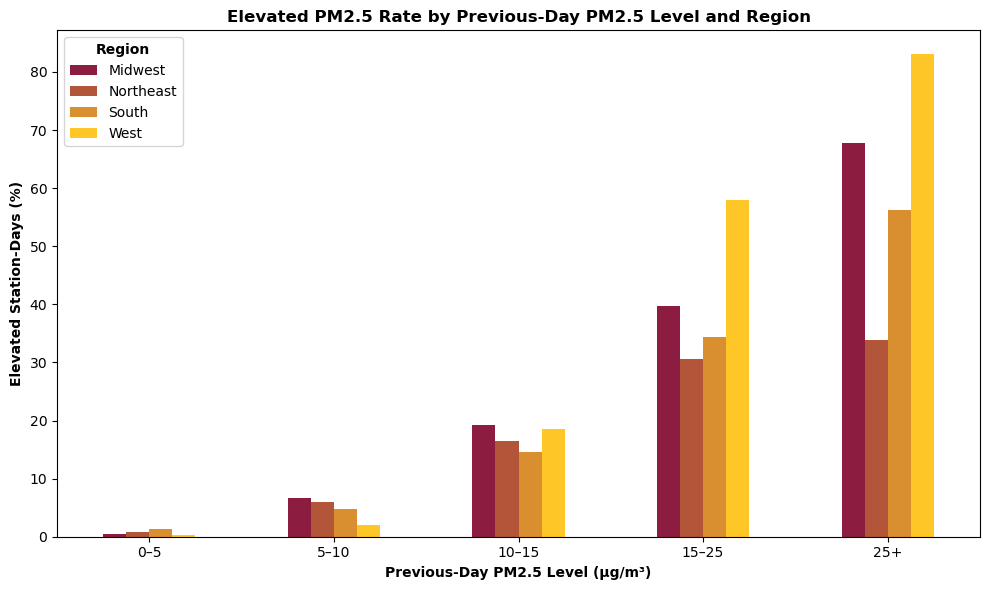

In [53]:
# Maroon → Gold gradient for the four regions
region_colors = maroon_gold(
    np.linspace(0, 1, len(tree_pattern.columns))
)

tree_pattern.plot(
    kind="bar",
    figsize=(10, 6),
    color=region_colors
)

plt.title(
    "Elevated PM2.5 Rate by Previous-Day PM2.5 Level and Region",
    fontweight="bold"
)

plt.xlabel(
    "Previous-Day PM2.5 Level (µg/m³)",
    fontweight="bold"
)

plt.ylabel(
    "Elevated Station-Days (%)",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.legend(
    title="Region",
    title_fontproperties={"weight": "bold"}
)

plt.tight_layout()
plt.show()

#### RQ1 Visual Interpretation

The visualizations show a clear relationship between previous-day PM2.5 and the likelihood of an elevated PM2.5 station-day. The percentage of elevated station-days increases substantially as previous-day PM2.5 moves into higher concentration ranges, supporting the use of **Logistic Regression** to examine elevated-pollution probability.

When previous-day PM2.5 is examined together with geographic region, the elevated-pollution rate also differs across regions, particularly at higher concentration levels. This suggests that classification may depend on combinations of recent pollution and geographic characteristics, supporting the use of a **Decision Tree** alongside Logistic Regression.

### RQ2: Current-Day and Next-Day PM2.5 Relationships.

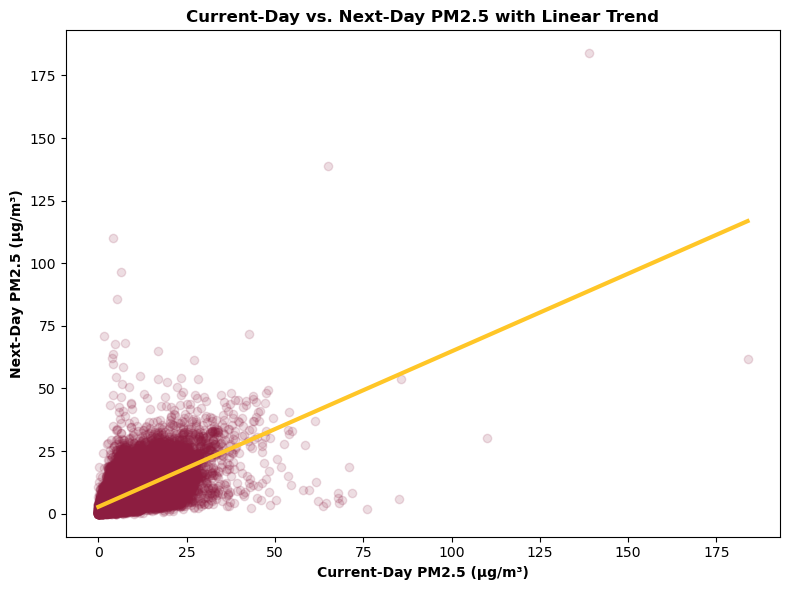

In [54]:
mlr_visual = station_daily[
    ["Arithmetic Mean", "Next Day PM2.5"]
].dropna().copy()

x = mlr_visual["Arithmetic Mean"]
y = mlr_visual["Next Day PM2.5"]

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

plt.figure(figsize=(8, 6))

# Maroon scatter points
plt.scatter(
    x,
    y,
    color="#8C1D40",
    alpha=0.15
)

# Gold linear trend
plt.plot(
    x_line,
    y_line,
    color="#FFC627",
    linewidth=3
)

plt.title(
    "Current-Day vs. Next-Day PM2.5 with Linear Trend",
    fontweight="bold"
)

plt.xlabel(
    "Current-Day PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.ylabel(
    "Next-Day PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### RQ2: Next-Day PM2.5 by Current Level and Region

In [55]:
rf_visual = station_daily[
    ["Arithmetic Mean", "Next Day PM2.5", "Region"]
].dropna().copy()

rf_visual["Current PM2.5 Level"] = pd.cut(
    rf_visual["Arithmetic Mean"],
    bins=[0, 5, 10, 15, 25, float("inf")],
    labels=["0–5", "5–10", "10–15", "15–25", "25+"],
    include_lowest=True
)

rf_pattern = (
    rf_visual.groupby(
        ["Current PM2.5 Level", "Region"],
        observed=True
    )["Next Day PM2.5"]
    .mean()
    .unstack()
)

rf_pattern.round(2)

Region,Midwest,Northeast,South,West
Current PM2.5 Level,,,,
0–5,4.88,4.96,5.43,3.48
5–10,7.78,7.57,7.82,6.75
10–15,10.56,9.85,10.27,11.09
15–25,13.69,12.07,13.29,16.37
25+,19.68,15.56,19.61,24.67


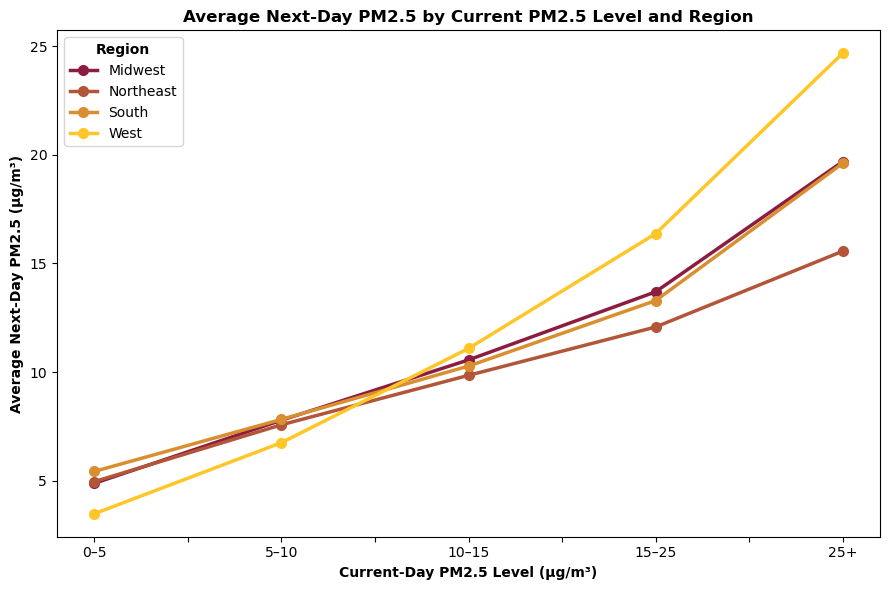

In [56]:
# Maroon → Gold gradient for the four regions
region_colors = maroon_gold(
    np.linspace(0, 1, len(rf_pattern.columns))
)

ax = rf_pattern.plot(
    kind="line",
    marker="o",
    figsize=(9, 6),
    color=region_colors,
    linewidth=2.5,
    markersize=7
)

plt.title(
    "Average Next-Day PM2.5 by Current PM2.5 Level and Region",
    fontweight="bold"
)

plt.xlabel(
    "Current-Day PM2.5 Level (µg/m³)",
    fontweight="bold"
)

plt.ylabel(
    "Average Next-Day PM2.5 (µg/m³)",
    fontweight="bold"
)

plt.legend(
    title="Region",
    title_fontproperties={"weight": "bold"}
)

plt.tight_layout()
plt.show()

#### Q2 Visual Interpretation

The current-day versus next-day PM2.5 scatterplot shows an overall positive linear trend, supporting the use of **Multiple Linear Regression** to evaluate how recent PM2.5 and other predictors relate to next-day concentrations. The spread of observations around the fitted line also indicates that current-day PM2.5 alone does not fully explain next-day variation.

When current-day PM2.5 is grouped by concentration level and region, average next-day concentrations increase across all four regions, but the patterns begin to separate at higher pollution levels. This suggests that geographic differences and more complex relationships may also be present, supporting the use of **Random Forest** as a flexible alternative to Multiple Linear Regression.

# Predictive Model Evaluation

## RQ1: Elevated PM2.5 Classification

Logistic Regression and Decision Tree Classification are evaluated to determine how well recent PM2.5 measurements and geographic and temporal characteristics can identify elevated-pollution station-days.

In [57]:
rq1_data = station_daily[
    [
        "Date Local",
        "Elevated PM2.5 (15)",
        "Previous Day PM2.5",
        "Latitude",
        "Longitude",
        "Day of Year",
        "Region"
    ]
].dropna().copy()

rq1_data = rq1_data.sort_values("Date Local").reset_index(drop=True)

print("RQ1 MODELING DATASET")
print("--------------------")
print("Usable observations:", len(rq1_data))

print(
    "Date range:",
    rq1_data["Date Local"].min(),
    "to",
    rq1_data["Date Local"].max()
)

print("\nCLASS DISTRIBUTION")
print("------------------")
print(rq1_data["Elevated PM2.5 (15)"].value_counts())

print("\nCLASS PERCENTAGES")
print("-----------------")
print(
    rq1_data["Elevated PM2.5 (15)"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

RQ1 MODELING DATASET
--------------------
Usable observations: 74149
Date range: 2026-01-02 00:00:00 to 2026-05-31 00:00:00

CLASS DISTRIBUTION
------------------
Elevated PM2.5 (15)
0    68314
1     5835
Name: count, dtype: Int64

CLASS PERCENTAGES
-----------------
Elevated PM2.5 (15)
0    92.13
1     7.87
Name: proportion, dtype: Float64


In [58]:
rq1_model = pd.get_dummies(
    rq1_data,
    columns=["Region"],
    drop_first=True,
    dtype=int
)

print("RQ1 MODELING VARIABLES")
print("----------------------")
print(rq1_model.columns.tolist())

RQ1 MODELING VARIABLES
----------------------
['Date Local', 'Elevated PM2.5 (15)', 'Previous Day PM2.5', 'Latitude', 'Longitude', 'Day of Year', 'Region_Northeast', 'Region_South', 'Region_West']


In [59]:
# Sort chronologically
rq1_model = rq1_model.sort_values("Date Local").reset_index(drop=True)

# Use approximately the first 80% of unique dates for training
unique_dates = rq1_model["Date Local"].sort_values().unique()

date_split_index = int(len(unique_dates) * 0.80)
cutoff_date = unique_dates[date_split_index]

train_rq1 = rq1_model[
    rq1_model["Date Local"] < cutoff_date
].copy()

test_rq1 = rq1_model[
    rq1_model["Date Local"] >= cutoff_date
].copy()

features_rq1 = [
    "Previous Day PM2.5",
    "Latitude",
    "Longitude",
    "Day of Year",
    "Region_Northeast",
    "Region_South",
    "Region_West"
]

X_train_rq1 = train_rq1[features_rq1]
X_test_rq1 = test_rq1[features_rq1]

y_train_rq1 = train_rq1["Elevated PM2.5 (15)"].astype(int)
y_test_rq1 = test_rq1["Elevated PM2.5 (15)"].astype(int)

print("RQ1 TIME-ORDERED TRAIN/TEST SPLIT")
print("---------------------------------")
print("Cutoff date:", cutoff_date)
print("Training observations:", len(train_rq1))
print("Testing observations:", len(test_rq1))

print(
    "\nTraining dates:",
    train_rq1["Date Local"].min(),
    "to",
    train_rq1["Date Local"].max()
)

print(
    "Testing dates:",
    test_rq1["Date Local"].min(),
    "to",
    test_rq1["Date Local"].max()
)

print(
    "\nDates appearing in both sets:",
    len(
        set(train_rq1["Date Local"]).intersection(
            set(test_rq1["Date Local"])
        )
    )
)

print("\nTRAINING CLASS DISTRIBUTION")
print(y_train_rq1.value_counts())
print((y_train_rq1.value_counts(normalize=True) * 100).round(2))

print("\nTESTING CLASS DISTRIBUTION")
print(y_test_rq1.value_counts())
print((y_test_rq1.value_counts(normalize=True) * 100).round(2))

RQ1 TIME-ORDERED TRAIN/TEST SPLIT
---------------------------------
Cutoff date: 2026-05-02 00:00:00
Training observations: 70717
Testing observations: 3432

Training dates: 2026-01-02 00:00:00 to 2026-05-01 00:00:00
Testing dates: 2026-05-02 00:00:00 to 2026-05-31 00:00:00

Dates appearing in both sets: 0

TRAINING CLASS DISTRIBUTION
Elevated PM2.5 (15)
0    64919
1     5798
Name: count, dtype: int64
Elevated PM2.5 (15)
0    91.8
1     8.2
Name: proportion, dtype: float64

TESTING CLASS DISTRIBUTION
Elevated PM2.5 (15)
0    3395
1      37
Name: count, dtype: int64
Elevated PM2.5 (15)
0    98.92
1     1.08
Name: proportion, dtype: float64


### Logistic Regression

Logistic Regression is used to estimate the probability that a station-day will be classified as elevated based on recent PM2.5, geographic, and temporal characteristics. Because elevated observations are much less common than non-elevated observations, performance is evaluated using precision, recall, F1 score, and ROC-AUC in addition to overall accuracy.

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train model
logistic_model.fit(X_train_rq1, y_train_rq1)

# Predictions
logistic_predictions = logistic_model.predict(X_test_rq1)
logistic_probabilities = logistic_model.predict_proba(X_test_rq1)[:, 1]

# Evaluation metrics
logistic_accuracy = accuracy_score(
    y_test_rq1,
    logistic_predictions
)

logistic_precision = precision_score(
    y_test_rq1,
    logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_test_rq1,
    logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test_rq1,
    logistic_predictions,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_test_rq1,
    logistic_probabilities
)

logistic_cm = confusion_matrix(
    y_test_rq1,
    logistic_predictions
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(logistic_accuracy, 3))
print("Precision:", round(logistic_precision, 3))
print("Recall:", round(logistic_recall, 3))
print("F1 Score:", round(logistic_f1, 3))
print("ROC-AUC:", round(logistic_auc, 3))

print("\nCONFUSION MATRIX")
print("----------------")
print(logistic_cm)

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.959
Precision: 0.145
Recall: 0.568
F1 Score: 0.231
ROC-AUC: 0.931

CONFUSION MATRIX
----------------
[[3271  124]
 [  16   21]]


### Decision Tree Classification

Decision Tree Classification is evaluated as a more flexible alternative to Logistic Regression. The model can identify nonlinear relationships and interactions among recent PM2.5, geographic, and temporal characteristics. Balanced class weights are used because elevated-pollution observations represent a small minority of the data.

In [61]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42
)

# Train model
tree_model.fit(X_train_rq1, y_train_rq1)

# Predictions
tree_predictions = tree_model.predict(X_test_rq1)
tree_probabilities = tree_model.predict_proba(X_test_rq1)[:, 1]

# Evaluation metrics
tree_accuracy = accuracy_score(
    y_test_rq1,
    tree_predictions
)

tree_precision = precision_score(
    y_test_rq1,
    tree_predictions,
    zero_division=0
)

tree_recall = recall_score(
    y_test_rq1,
    tree_predictions,
    zero_division=0
)

tree_f1 = f1_score(
    y_test_rq1,
    tree_predictions,
    zero_division=0
)

tree_auc = roc_auc_score(
    y_test_rq1,
    tree_probabilities
)

tree_cm = confusion_matrix(
    y_test_rq1,
    tree_predictions
)

print("DECISION TREE RESULTS")
print("---------------------")
print("Accuracy:", round(tree_accuracy, 3))
print("Precision:", round(tree_precision, 3))
print("Recall:", round(tree_recall, 3))
print("F1 Score:", round(tree_f1, 3))
print("ROC-AUC:", round(tree_auc, 3))

print("\nCONFUSION MATRIX")
print("----------------")
print(tree_cm)

DECISION TREE RESULTS
---------------------
Accuracy: 0.97
Precision: 0.125
Recall: 0.297
F1 Score: 0.176
ROC-AUC: 0.468

CONFUSION MATRIX
----------------
[[3318   77]
 [  26   11]]


## RQ1 Random Forest

In [62]:
from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_classifier.fit(X_train_rq1, y_train_rq1)

# Predictions
rf_class_predictions = rf_classifier.predict(X_test_rq1)
rf_class_probabilities = rf_classifier.predict_proba(X_test_rq1)[:, 1]

# Evaluation metrics
rf_class_accuracy = accuracy_score(
    y_test_rq1,
    rf_class_predictions
)

rf_class_precision = precision_score(
    y_test_rq1,
    rf_class_predictions,
    zero_division=0
)

rf_class_recall = recall_score(
    y_test_rq1,
    rf_class_predictions,
    zero_division=0
)

rf_class_f1 = f1_score(
    y_test_rq1,
    rf_class_predictions,
    zero_division=0
)

rf_class_auc = roc_auc_score(
    y_test_rq1,
    rf_class_probabilities
)

rf_class_cm = confusion_matrix(
    y_test_rq1,
    rf_class_predictions
)

print("RANDOM FOREST CLASSIFICATION RESULTS")
print("------------------------------------")
print("Accuracy:", round(rf_class_accuracy, 3))
print("Precision:", round(rf_class_precision, 3))
print("Recall:", round(rf_class_recall, 3))
print("F1 Score:", round(rf_class_f1, 3))
print("ROC-AUC:", round(rf_class_auc, 3))

print("\nCONFUSION MATRIX")
print("----------------")
print(rf_class_cm)

RANDOM FOREST CLASSIFICATION RESULTS
------------------------------------
Accuracy: 0.989
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.804

CONFUSION MATRIX
----------------
[[3395    0]
 [  37    0]]


### Classification Model Comparison

Logistic Regression, Decision Tree, and Random Forest were evaluated on the same time-ordered testing period.

In [63]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        rf_class_accuracy
    ],
    "Precision": [
        logistic_precision,
        tree_precision,
        rf_class_precision
    ],
    "Recall": [
        logistic_recall,
        tree_recall,
        rf_class_recall
    ],
    "F1 Score": [
        logistic_f1,
        tree_f1,
        rf_class_f1
    ],
    "ROC-AUC": [
        logistic_auc,
        tree_auc,
        rf_class_auc
    ]
})

classification_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.959,0.145,0.568,0.231,0.931
1,Decision Tree,0.970,0.125,0.297,0.176,0.468
2,Random Forest,0.989,0.000,0.000,0.000,0.804


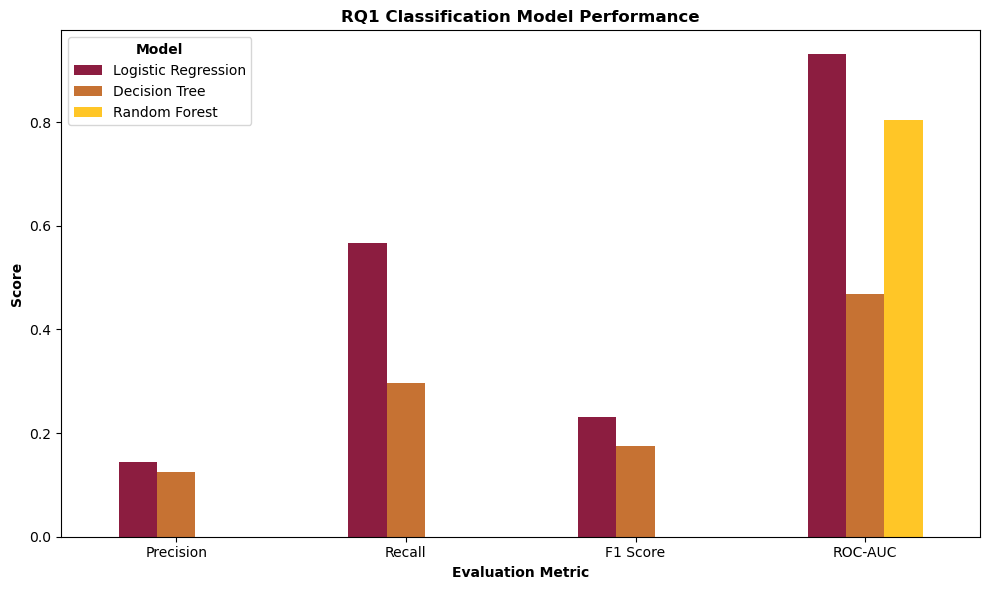

In [64]:
classification_plot = classification_results.set_index("Model")[
    ["Precision", "Recall", "F1 Score", "ROC-AUC"]
]

model_colors = maroon_gold(
    np.linspace(0, 1, 3)
)

classification_plot.T.plot(
    kind="bar",
    figsize=(10, 6),
    color=model_colors
)

plt.title(
    "RQ1 Classification Model Performance",
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metric",
    fontweight="bold"
)

plt.ylabel(
    "Score",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.legend(
    title="Model",
    title_fontproperties={"weight": "bold"}
)

plt.tight_layout()
plt.show()

## RQ2: Next-Day PM2.5 Prediction

### Modeling Dataset

In [65]:
rq3_data = station_daily[
    [
        "Date Local",
        "Arithmetic Mean",
        "Previous Day PM2.5",
        "Next Day PM2.5",
        "Latitude",
        "Longitude",
        "Day of Year",
        "Region"
    ]
].dropna().copy()

rq3_data = rq3_data.sort_values("Date Local").reset_index(drop=True)

print("RQ2 MODELING DATASET")
print("--------------------")
print("Usable observations:", len(rq3_data))
print(
    "Date range:",
    rq3_data["Date Local"].min(),
    "to",
    rq3_data["Date Local"].max()
)

RQ2 MODELING DATASET
--------------------
Usable observations: 72504
Date range: 2026-01-02 00:00:00 to 2026-05-30 00:00:00


### Modeling Variables

In [66]:
rq3_model = pd.get_dummies(
    rq3_data,
    columns=["Region"],
    drop_first=True,
    dtype=int
)

print("RQ3 MODELING VARIABLES")
print("----------------------")
print(rq3_model.columns.tolist())

RQ3 MODELING VARIABLES
----------------------
['Date Local', 'Arithmetic Mean', 'Previous Day PM2.5', 'Next Day PM2.5', 'Latitude', 'Longitude', 'Day of Year', 'Region_Northeast', 'Region_South', 'Region_West']


### Time-Ordered Train/Test Split

In [67]:
# Sort chronologically
rq3_model = rq3_model.sort_values("Date Local").reset_index(drop=True)

# Use approximately the first 80% of unique dates for training
unique_dates = rq3_model["Date Local"].sort_values().unique()

date_split_index = int(len(unique_dates) * 0.80)
cutoff_date = unique_dates[date_split_index]

train = rq3_model[rq3_model["Date Local"] < cutoff_date].copy()
test = rq3_model[rq3_model["Date Local"] >= cutoff_date].copy()

features = [
    "Arithmetic Mean",
    "Previous Day PM2.5",
    "Latitude",
    "Longitude",
    "Day of Year",
    "Region_Northeast",
    "Region_South",
    "Region_West"
]

X_train = train[features]
X_test = test[features]

y_train = train["Next Day PM2.5"]
y_test = test["Next Day PM2.5"]

print("TIME-ORDERED TRAIN/TEST SPLIT")
print("-----------------------------")
print("Cutoff date:", cutoff_date)
print("Training observations:", len(train))
print("Testing observations:", len(test))

print(
    "\nTraining dates:",
    train["Date Local"].min(),
    "to",
    train["Date Local"].max()
)

print(
    "Testing dates:",
    test["Date Local"].min(),
    "to",
    test["Date Local"].max()
)

print(
    "\nDates appearing in both sets:",
    len(
        set(train["Date Local"]).intersection(
            set(test["Date Local"])
        )
    )
)# Sort chronologically
rq3_model = rq3_model.sort_values("Date Local").reset_index(drop=True)

# Use approximately the first 80% of unique dates for training
unique_dates = rq3_model["Date Local"].sort_values().unique()

date_split_index = int(len(unique_dates) * 0.80)
cutoff_date = unique_dates[date_split_index]

train = rq3_model[rq3_model["Date Local"] < cutoff_date].copy()
test = rq3_model[rq3_model["Date Local"] >= cutoff_date].copy()

features = [
    "Arithmetic Mean",
    "Previous Day PM2.5",
    "Latitude",
    "Longitude",
    "Day of Year",
    "Region_Northeast",
    "Region_South",
    "Region_West"
]

X_train = train[features]
X_test = test[features]

y_train = train["Next Day PM2.5"]
y_test = test["Next Day PM2.5"]

print("TIME-ORDERED TRAIN/TEST SPLIT")
print("-----------------------------")
print("Cutoff date:", cutoff_date)
print("Training observations:", len(train))
print("Testing observations:", len(test))

print(
    "\nTraining dates:",
    train["Date Local"].min(),
    "to",
    train["Date Local"].max()
)

print(
    "Testing dates:",
    test["Date Local"].min(),
    "to",
    test["Date Local"].max()
)

print(
    "\nDates appearing in both sets:",
    len(
        set(train["Date Local"]).intersection(
            set(test["Date Local"])
        )
    )
)

TIME-ORDERED TRAIN/TEST SPLIT
-----------------------------
Cutoff date: 2026-05-01 00:00:00
Training observations: 69114
Testing observations: 3390

Training dates: 2026-01-02 00:00:00 to 2026-04-30 00:00:00
Testing dates: 2026-05-01 00:00:00 to 2026-05-30 00:00:00

Dates appearing in both sets: 0
TIME-ORDERED TRAIN/TEST SPLIT
-----------------------------
Cutoff date: 2026-05-01 00:00:00
Training observations: 69114
Testing observations: 3390

Training dates: 2026-01-02 00:00:00 to 2026-04-30 00:00:00
Testing dates: 2026-05-01 00:00:00 to 2026-05-30 00:00:00

Dates appearing in both sets: 0


### Multiple Linear Regression

Multiple Linear Regression is used as the first method for predicting next-day PM2.5 concentration. The model uses current and previous-day PM2.5 measurements along with geographic and temporal characteristics as predictors.

In [68]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mlr = LinearRegression()

# Train model
mlr.fit(X_train, y_train)

# Predict the later testing period
mlr_predictions = mlr.predict(X_test)

# Evaluate performance
mlr_mae = mean_absolute_error(y_test, mlr_predictions)
mlr_rmse = np.sqrt(mean_squared_error(y_test, mlr_predictions))
mlr_r2 = r2_score(y_test, mlr_predictions)

print("MULTIPLE LINEAR REGRESSION RESULTS")
print("----------------------------------")
print("MAE:", round(mlr_mae, 3))
print("RMSE:", round(mlr_rmse, 3))
print("R²:", round(mlr_r2, 3))

MULTIPLE LINEAR REGRESSION RESULTS
----------------------------------
MAE: 1.668
RMSE: 2.259
R²: 0.307


### Decision Tree Regression

In [69]:
from sklearn.tree import DecisionTreeRegressor

decision_tree_reg = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

# Train model
decision_tree_reg.fit(X_train, y_train)

# Predict testing period
dt_predictions = decision_tree_reg.predict(X_test)

# Evaluate performance
dt_mae = mean_absolute_error(
    y_test,
    dt_predictions
)

dt_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        dt_predictions
    )
)

dt_r2 = r2_score(
    y_test,
    dt_predictions
)

print("DECISION TREE REGRESSION RESULTS")
print("--------------------------------")
print("MAE:", round(dt_mae, 3))
print("RMSE:", round(dt_rmse, 3))
print("R²:", round(dt_r2, 3))

DECISION TREE REGRESSION RESULTS
--------------------------------
MAE: 1.842
RMSE: 2.417
R²: 0.207


### Random Forest Regression

Random Forest Regression is used as a more flexible method for predicting next-day PM2.5. Unlike Multiple Linear Regression, Random Forest can capture nonlinear relationships and interactions among recent PM2.5, geographic, and temporal characteristics.

In [70]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train model
rf.fit(X_train, y_train)

# Predict the later testing period
rf_predictions = rf.predict(X_test)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST REGRESSION RESULTS")
print("--------------------------------")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R²:", round(rf_r2, 3))

RANDOM FOREST REGRESSION RESULTS
--------------------------------
MAE: 1.912
RMSE: 2.718
R²: -0.003


### Model Performance Comparison

In [71]:
model_results = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Decision Tree Regression",
        "Random Forest"
    ],
    "MAE": [
        1.668,
        1.842,
        1.912
    ],
    "RMSE": [
        2.259,
        2.417,
        2.718
    ],
    "R²": [
        0.307,
        0.207,
        -0.003
    ]
})

print(model_results)

                        Model    MAE   RMSE     R²
0  Multiple Linear Regression  1.668  2.259  0.307
1    Decision Tree Regression  1.842  2.417  0.207
2               Random Forest  1.912  2.718 -0.003


### Prediction Error Comparison

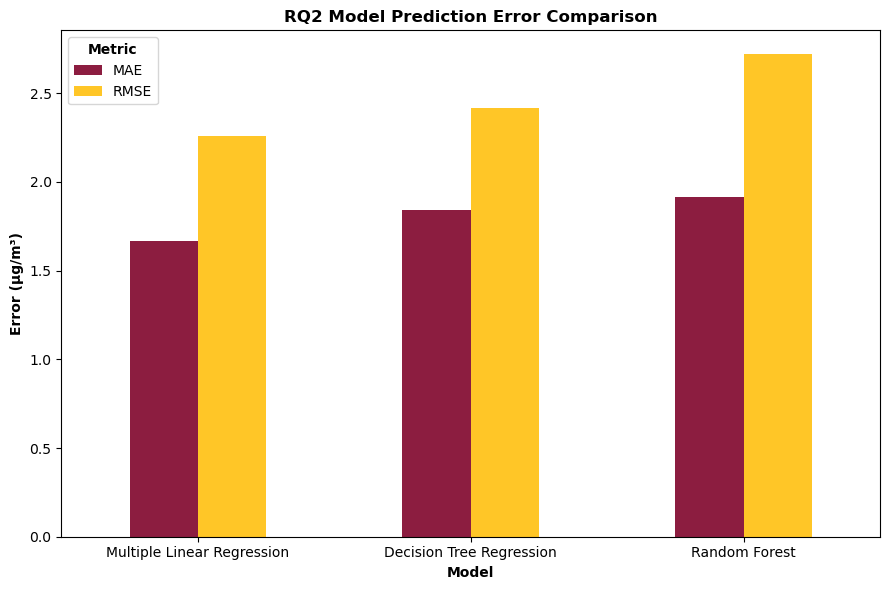

In [72]:
error_comparison = model_results.set_index("Model")[["MAE", "RMSE"]]

error_comparison.plot(
    kind="bar",
    figsize=(9, 6),
    color=["#8C1D40", "#FFC627"]
)

plt.title(
    "RQ2 Model Prediction Error Comparison",
    fontweight="bold"
)

plt.xlabel(
    "Model",
    fontweight="bold"
)

plt.ylabel(
    "Error (µg/m³)",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.legend(
    title="Metric",
    title_fontproperties={"weight": "bold"}
)

plt.tight_layout()
plt.show()

### R$^2$ Comparison

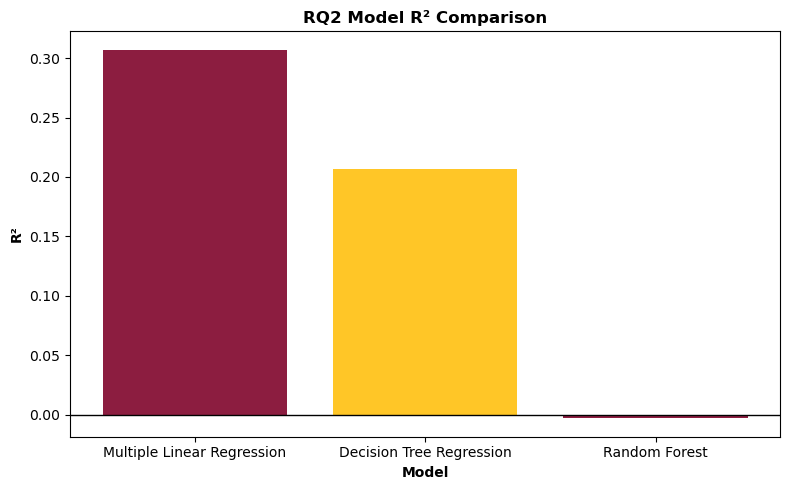

In [73]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["R²"],
    color=["#8C1D40", "#FFC627"]
)

# Zero reference line
plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "RQ2 Model R² Comparison",
    fontweight="bold"
)

plt.xlabel(
    "Model",
    fontweight="bold"
)

plt.ylabel(
    "R²",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Regional Model Performance

Because RQ2 asks whether predictive performance varies across U.S. regions, model performance is also evaluated separately for the Midwest, Northeast, South, and West using MAE, RMSE, and R².

In [74]:
regional_results = []

# Add region labels back to the test data
regional_test = rq3_data.loc[test.index, ["Region"]].copy()

regional_test["Actual"] = y_test.values
regional_test["MLR Prediction"] = mlr_predictions
regional_test["DT Prediction"] = dt_predictions
regional_test["RF Prediction"] = rf_predictions

for region in ["Midwest", "Northeast", "South", "West"]:

    region_data = regional_test[
        regional_test["Region"] == region
    ]

    actual = region_data["Actual"]

    for model_name, prediction_column in [
        ("Multiple Linear Regression", "MLR Prediction"),
        ("Decision Tree Regression", "DT Prediction"),
        ("Random Forest", "RF Prediction")
    ]:

        predictions = region_data[prediction_column]

        regional_results.append({
            "Region": region,
            "Model": model_name,
            "Observations": len(region_data),
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
            "R²": r2_score(actual, predictions)
        })

regional_performance = pd.DataFrame(regional_results)

regional_performance.round(3)

,Region,Model,Observations,MAE,RMSE,R²
0,Midwest,Multiple Linear Regression,551,1.603,2.100,0.318
1,Midwest,Decision Tree Regression,551,1.771,2.324,0.165
2,Midwest,Random Forest,551,1.831,2.558,-0.012
3,Northeast,Multiple Linear Regression,767,1.890,2.602,0.269
4,Northeast,Decision Tree Regression,767,2.063,2.727,0.198
5,Northeast,Random Forest,767,2.124,3.007,0.024
6,South,Multiple Linear Regression,1222,1.590,2.114,0.323
7,South,Decision Tree Regression,1222,1.786,2.294,0.203
8,South,Random Forest,1222,1.871,2.733,-0.132
9,West,Multiple Linear Regression,850,1.622,2.227,0.319


### Regional MAE Comparison

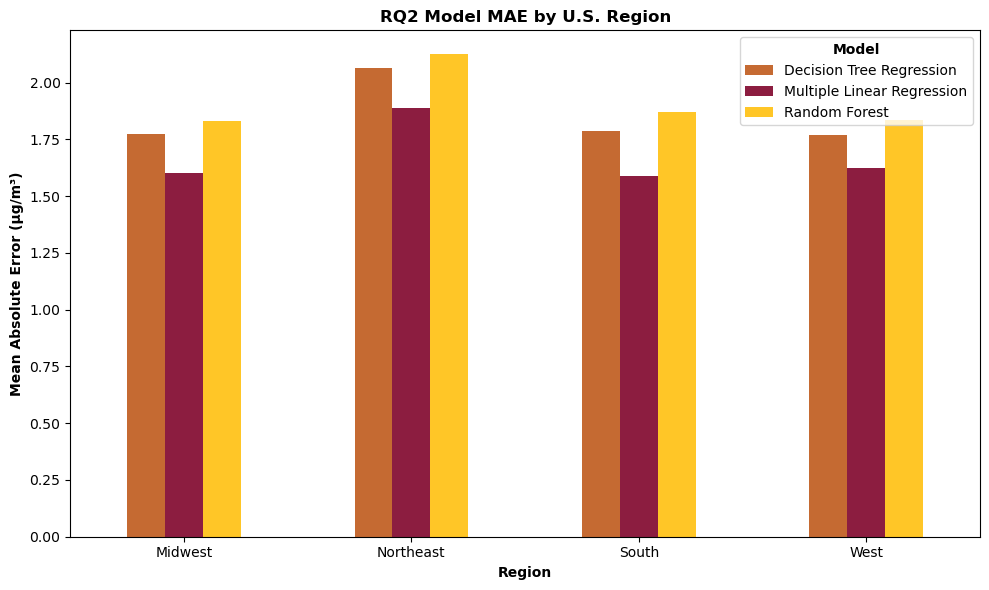

In [75]:
regional_mae = regional_performance.pivot(
    index="Region",
    columns="Model",
    values="MAE"
)

# Maroon → Gold gradient for the three models
model_colors = {
    "Multiple Linear Regression": "#8C1D40",
    "Decision Tree Regression": "#C56A32",
    "Random Forest": "#FFC627"
}

regional_mae.plot(
    kind="bar",
    figsize=(10, 6),
    color=[model_colors[col] for col in regional_mae.columns]
)

plt.title(
    "RQ2 Model MAE by U.S. Region",
    fontweight="bold"
)

plt.xlabel(
    "Region",
    fontweight="bold"
)

plt.ylabel(
    "Mean Absolute Error (µg/m³)",
    fontweight="bold"
)

plt.xticks(rotation=0)

plt.legend(
    title="Model",
    title_fontproperties={"weight": "bold"}
)

plt.tight_layout()
plt.show()

#### Regional Performance Results

Mean Absolute Error (MAE) was compared across regions to determine whether prediction accuracy varied geographically. MAE represents the average difference between predicted and actual next-day PM2.5 concentrations, so lower values indicate better predictive accuracy.

Multiple Linear Regression produced lower MAE than Random Forest in all four regions. For Multiple Linear Regression, the South had the lowest MAE (1.590 µg/m³), while the Northeast had the highest (1.890 µg/m³). These results show that predictive performance varies across regions, with the Northeast showing somewhat larger prediction errors than the other regions.

Overall, the regional results further support Multiple Linear Regression as the better-performing model for RQ3 under the time-ordered validation approach.